In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

In [2]:
from google.colab import files

uploaded = files.upload()

Saving height-weight.csv to height-weight.csv


In [6]:
df= pd.read_csv("height-weight.csv")
df.head()

,Weight,Height
0,45,120
1,58,135
2,48,123
3,60,145
4,70,160


Text(0.5, 1.0, 'Height vs Weight')

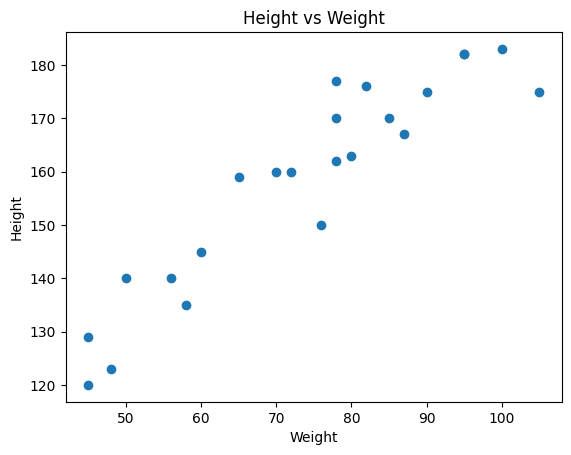

In [9]:
plt.scatter(df['Weight'], df['Height'])
plt.xlabel("Weight")
plt.ylabel("Height")
plt.title("Height vs Weight")

In [11]:
##divide our dataset into independent and dependent features
x= df['Weight']
y= df['Height']

In [71]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test= train_test_split(x,y, test_size=0.20, random_state=42)

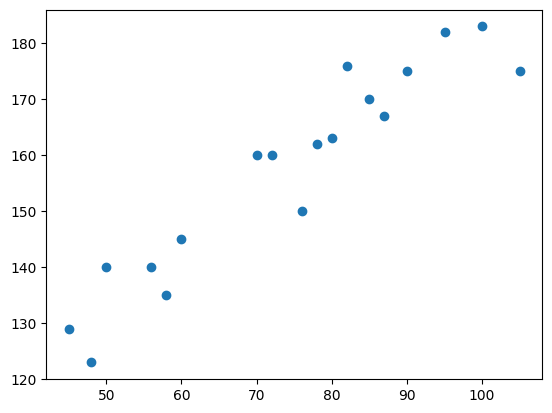

In [72]:
plt.scatter(x_train,y_train)

In [73]:
x_train

,Weight
12,105
1,58
13,100
5,78
2,48
11,95
20,45
3,60
4,70
18,76


In [19]:
x_test

,Weight
15,78
9,78
0,45
8,95
17,65


In [20]:
y_train

,Height
12,175
1,135
13,183
5,162
2,123
11,182
20,129
3,145
4,160
18,150


In [21]:
y_test

,Height
15,177
9,170
0,120
8,182
17,159


In [30]:
x_train.shape



(18,)

In [74]:
x_train= x_train.values.reshape(-1,1)
x_test= x_test.values.reshape(-1,1)

In [35]:
x_test.shape

(5, 1)

In [75]:
x_train

array([[105],
       [ 58],
       [100],
       [ 78],
       [ 48],
       [ 95],
       [ 45],
       [ 60],
       [ 70],
       [ 76],
       [ 50],
       [ 56],
       [ 72],
       [ 90],
       [ 82],
       [ 85],
       [ 87],
       [ 80]])

In [76]:
## Standardize the dataset
from sklearn.preprocessing import StandardScaler
scaler= StandardScaler()
x_train= scaler.fit_transform(x_train)
x_test= scaler.transform(x_test)

In [38]:
y_train.shape

(18,)

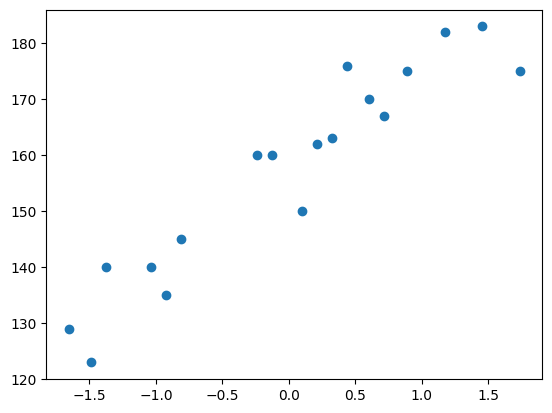

In [41]:
plt.scatter(x_train,y_train)

In [42]:
print("Mean:", np.mean(x_train))
print("Standard Deviation:", np.std(x_train))

Mean: -3.0839528461809905e-17
Standard Deviation: 1.0


In [43]:
from sklearn.linear_model import LinearRegression
regressor= LinearRegression()

In [44]:
regressor

LinearRegression()

In [45]:
type(x_train)

numpy.ndarray

In [47]:
##training time
regressor.fit(x_train,y_train)

LinearRegression()

In [48]:
## coefficient and intercepts
print("Coefficient : ",regressor.coef_)
print("Intercept : ",regressor.intercept_)

Coefficient :  [17.03440872]
Intercept :  157.5


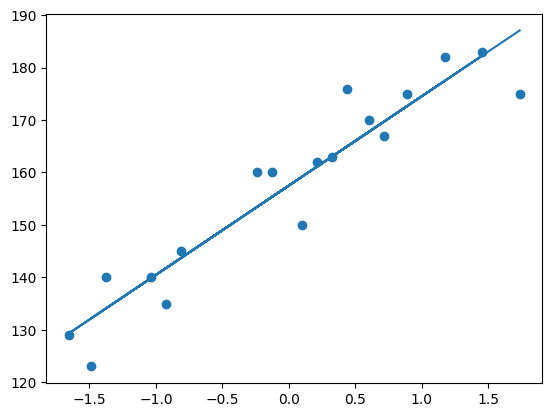

In [50]:
plt.scatter(x_train,y_train)
plt.plot(x_train,regressor.predict(x_train))

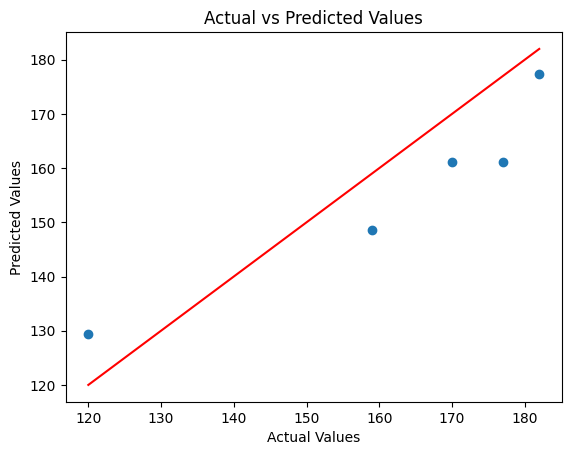

In [77]:
y_pred_test=regressor.predict(x_test)
plt.scatter(y_test, y_pred_test)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red'
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Values")
plt.show()

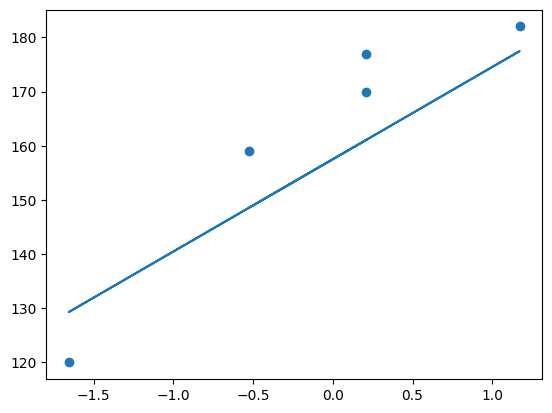

In [61]:
plt.scatter(x_test,y_test)
plt.plot(x_test,regressor.predict(x_test))

In [63]:
### Performance metrics

from sklearn.metrics import mean_squared_error,mean_absolute_error

In [64]:
mse=mean_squared_error(y_test,y_pred_test)
mae=mean_absolute_error(y_test,y_pred_test)
rmse=np.sqrt(mse)
print(mse)
print(mae)
print(rmse)

109.77592599051658
9.822657814519232
10.477400726827078


In [65]:
from sklearn.metrics import r2_score
score=r2_score(y_test,y_pred_test)
print(score)

0.776986986042344


In [67]:

#display adjusted R-squared
1 - (1-score)*(len(y_test)-1)/(len(y_test)-x_test.shape[1]-1)

0.7026493147231252

In [78]:
regressor.predict(scaler.transform([[75]]))


array([158.19553315])

In [79]:
## Residuals
residuals=y_test-y_pred_test

residuals

,Height
15,15.915329
9,8.915329
0,-9.304156
8,4.543549
17,10.434926


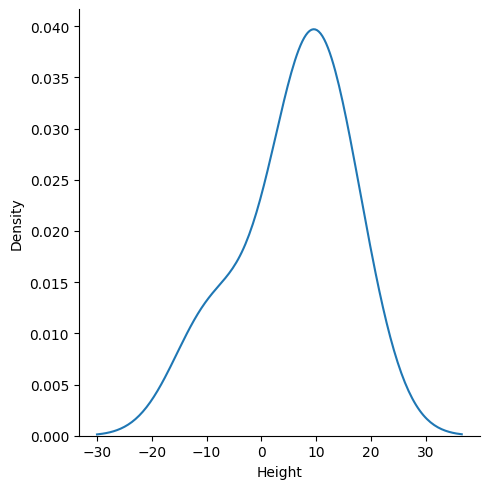

In [80]:
## Plot this residuals
import seaborn as sns
sns.displot(residuals,kind="kde")

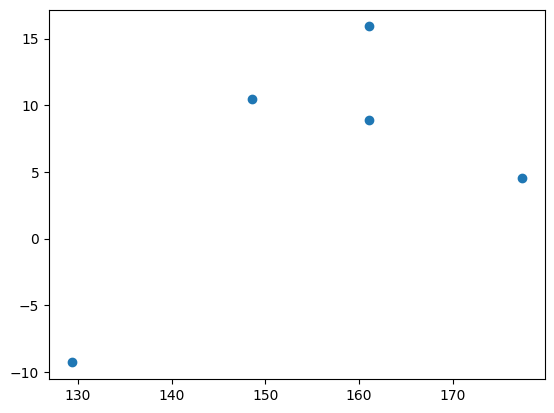

In [81]:
## Scatter plot with respect to prediction and residuals
## uniform distribution
plt.scatter(y_pred_test,residuals)

Using **OLS**

In [82]:
import statsmodels.api as sm
model= sm.OLS(y_train, x_train).fit()
predictions = model.predict(x_test)

In [83]:
print(model.summary())

                                 OLS Regression Results                                
Dep. Variable:                 Height   R-squared (uncentered):                   0.012
Model:                            OLS   Adj. R-squared (uncentered):             -0.047
Method:                 Least Squares   F-statistic:                             0.1986
Date:                Thu, 19 Nov 2026   Prob (F-statistic):                       0.661
Time:                        20:55:27   Log-Likelihood:                         -116.62
No. Observations:                  18   AIC:                                      235.2
Df Residuals:                      17   BIC:                                      236.1
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------